# GLP-1 Market Sizing and Prescriber Targeting in Medicare Part D

**Business question:** A GLP-1 brand team has a fixed field force. Where is the
remaining growth in Medicare, and which prescribers should reps call on first?

**Data:** CMS Medicare Part D Prescribers, by Provider and Drug (2022–2024) and
by Geography and Drug (2018–2024). Every row is a real prescriber or state, drug
and year, as published by CMS.

**Terms used:**
- **GLP-1** (glucagon-like peptide-1) agonists lower blood sugar and body weight:
  Ozempic, Rybelsus and Wegovy (semaglutide), Mounjaro and Zepbound (tirzepatide,
  which also acts on the GIP receptor), Trulicity, Victoza and others.
- **SGLT2** inhibitors (Jardiance, Farxiga) and **DPP-4** inhibitors (Januvia,
  Tradjenta) are the other modern, branded type 2 diabetes classes. A prescriber
  writing any of the three is treating type 2 diabetes with modern therapy, which
  makes them a GLP-1 prospect.
- **Claim**: one prescription fill paid by a Part D plan.
- **Gross drug cost**: what plans and patients paid at the pharmacy, *before*
  manufacturer rebates. It overstates manufacturer revenue but is the best public
  measure of market size.
- CMS hides any prescriber–drug row with fewer than 11 claims to protect patient
  privacy, so very low-volume prescribers are missing.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path.cwd() if Path.cwd().name.startswith("01-") else Path("01-glp1-market-and-targeting")
sys.path.insert(0, str(HERE.parent))
from common import style  # noqa: E402

style.apply()
RAW, FIG, TAB = HERE / "data" / "raw", HERE / "outputs" / "figures", HERE / "outputs" / "tables"
TAB.mkdir(parents=True, exist_ok=True)
SRC = "CMS Medicare Part D Prescribers by Provider and Drug / by Geography and Drug"

CLASS_TERMS = {
    "GLP-1": ["semaglutide", "tirzepatide", "dulaglutide", "liraglutide", "exenatide", "lixisenatide"],
    "SGLT2": ["empagliflozin", "dapagliflozin", "canagliflozin", "ertugliflozin", "bexagliflozin"],
    "DPP-4": ["sitagliptin", "linagliptin", "saxagliptin", "alogliptin"],
}


def drug_class(generic: str) -> str:
    g = str(generic).lower()
    for cls, terms in CLASS_TERMS.items():   # GLP-1 first: combos with insulin count as GLP-1
        if any(t in g for t in terms):
            return cls
    return "Other"


def brand_group(brand: str, generic: str) -> str:
    b, g = str(brand).lower(), str(generic).lower()
    for key, label in [("ozempic", "Ozempic"), ("wegovy", "Wegovy"), ("rybelsus", "Rybelsus"),
                       ("mounjaro", "Mounjaro"), ("zepbound", "Zepbound"), ("trulicity", "Trulicity"),
                       ("victoza", "Victoza"), ("saxenda", "Saxenda")]:
        if key in b:
            return label
    if "liraglutide" in g and ("insulin" not in g):
        return "Liraglutide (generic)"
    return "Other GLP-1"


NUM = ["Tot_Clms", "Tot_30day_Fills", "Tot_Day_Suply", "Tot_Drug_Cst", "Tot_Benes", "Tot_Prscrbrs"]


def load(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, dtype=str)
    for c in NUM:
        if c in df:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    df["cls"] = df["Gnrc_Name"].map(drug_class)
    df["brand"] = np.where(df["cls"] == "GLP-1",
                           [brand_group(b, g) for b, g in zip(df["Brnd_Name"], df["Gnrc_Name"])], df["Brnd_Name"])
    return df

## 1. Market size: Medicare GLP-1 spend has grown several-fold since 2018

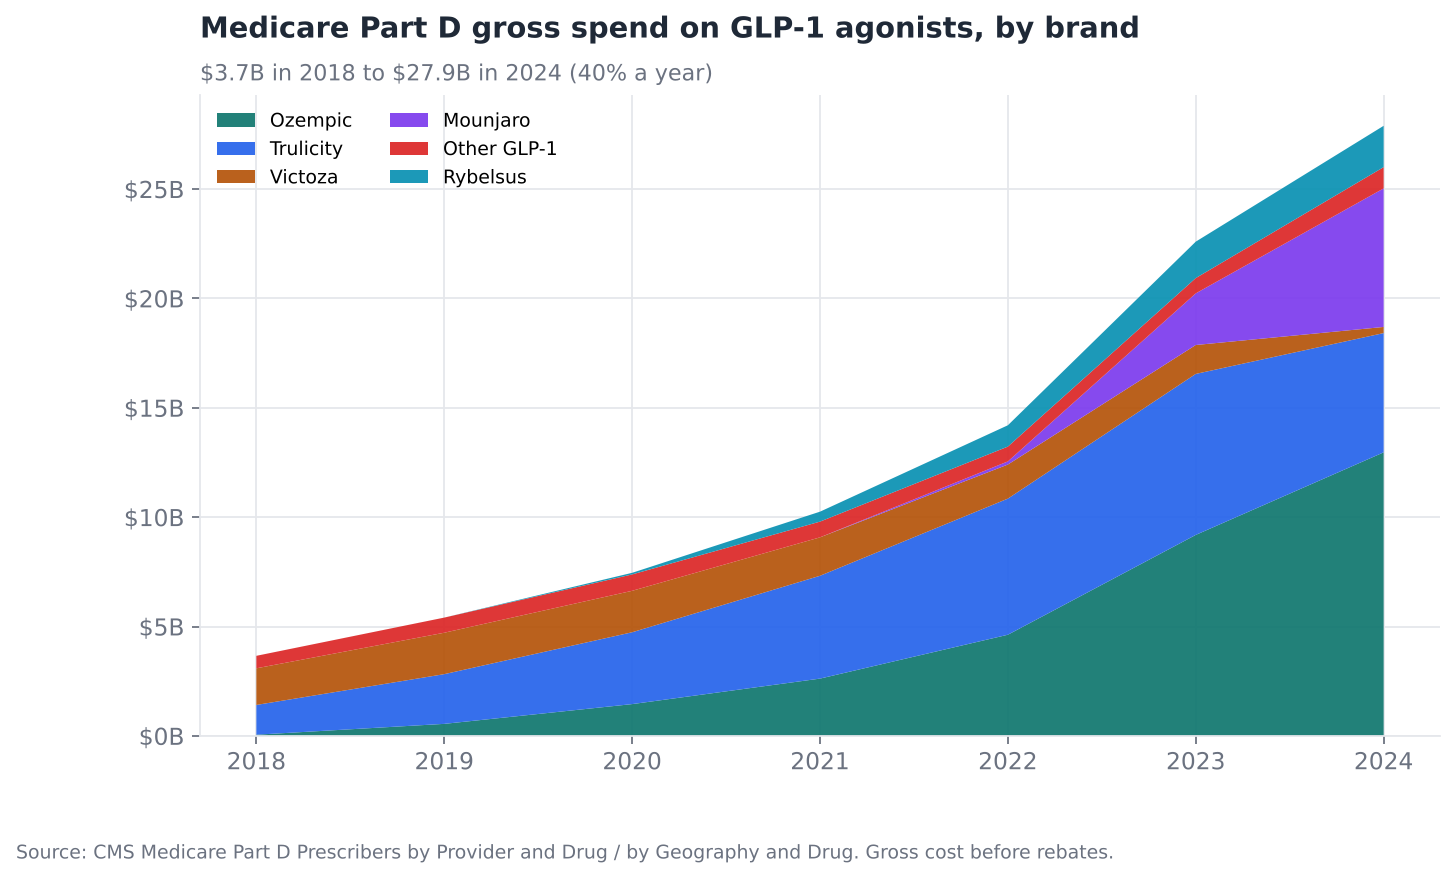

brand,Ozempic,Trulicity,Victoza,Mounjaro,Other GLP-1,Rybelsus
year,,,,,,
2018,57.0,1360.0,1675.0,0.0,571.0,0.0
2019,552.0,2273.0,1894.0,0.0,692.0,0.0
2020,1456.0,3284.0,1895.0,0.0,749.0,73.0
2021,2621.0,4701.0,1757.0,0.0,720.0,454.0
2022,4627.0,6223.0,1557.0,144.0,677.0,975.0
2023,9191.0,7361.0,1321.0,2361.0,699.0,1665.0
2024,12966.0,5452.0,281.0,6335.0,972.0,1889.0


In [2]:
geo = pd.concat([load(f).assign(year=int(f.name[9:13])) for f in sorted(RAW.glob("geo_drug_*.csv.gz"))])
nat = geo[geo["Prscrbr_Geo_Lvl"] == "National"]
trend = nat[nat["cls"] == "GLP-1"].pivot_table(index="year", columns="brand", values="Tot_Drug_Cst", aggfunc="sum").fillna(0)
# Fold brands that never reach 2% of class spend into 'Other GLP-1' (Part D does not
# cover drugs used only for weight loss, so Saxenda and Zepbound barely appear)
small = trend.columns[(trend.div(trend.sum(axis=1), axis=0).max() < 0.02)]
trend["Other GLP-1"] = trend.get("Other GLP-1", 0) + trend[small].sum(axis=1)
trend = trend.drop(columns=[c for c in small if c != "Other GLP-1"])
trend = trend[trend.sum().sort_values(ascending=False).index]
cls_trend = nat.pivot_table(index="year", columns="cls", values=["Tot_Drug_Cst", "Tot_Clms"], aggfunc="sum")

fig, ax = plt.subplots(figsize=(10, 5.2))
ax.stackplot(trend.index, trend.T.values, labels=trend.columns, colors=style.PALETTE[:len(trend.columns)], alpha=0.92)
ax.set_title("Medicare Part D gross spend on GLP-1 agonists, by brand")
first, last = trend.index.min(), trend.index.max()
growth = trend.sum(axis=1)
style.subtitle(ax, f"${growth[first] / 1e9:,.1f}B in {first} to ${growth[last] / 1e9:,.1f}B in {last}"
               f" ({(growth[last] / growth[first]) ** (1 / (last - first)) - 1:.0%} a year)")
style.dollars(ax)
ax.set_xticks(trend.index)
ax.legend(loc="upper left", fontsize=8.5, ncol=2)
style.source(fig, SRC + ". Gross cost before rebates.")
style.save(fig, FIG / "01_glp1_spend_by_brand.png")
(trend / 1e6).round(0)

In [3]:
share = trend.div(trend.sum(axis=1), axis=0)
share.round(3).T

year,2018,2019,2020,2021,2022,2023,2024
brand,,,,,,,
Ozempic,0.016,0.102,0.195,0.256,0.326,0.407,0.465
Trulicity,0.371,0.420,0.440,0.458,0.438,0.326,0.195
Victoza,0.457,0.350,0.254,0.171,0.110,0.058,0.010
Mounjaro,0.000,0.000,0.000,0.000,0.010,0.104,0.227
Other GLP-1,0.156,0.128,0.100,0.070,0.048,0.031,0.035
Rybelsus,0.000,0.000,0.010,0.044,0.069,0.074,0.068


Context against the other modern diabetes classes (claims, millions):

In [4]:
(cls_trend["Tot_Clms"] / 1e6).round(2)

cls,DPP-4,GLP-1,SGLT2
year,,,
2018,8.77,3.65,2.60
2019,8.70,4.95,3.40
2020,8.42,6.25,4.62
2021,8.00,7.94,6.41
2022,7.50,10.40,9.40
2023,7.00,16.55,13.36
2024,6.90,22.16,18.35


## 2. GLP-1 penetration varies sharply by state

**GLP-1 penetration** = GLP-1 claims ÷ all GLP-1 + SGLT2 + DPP-4 claims. It shows
how much of modern type 2 diabetes treatment already goes to GLP-1s, without
needing state population data.

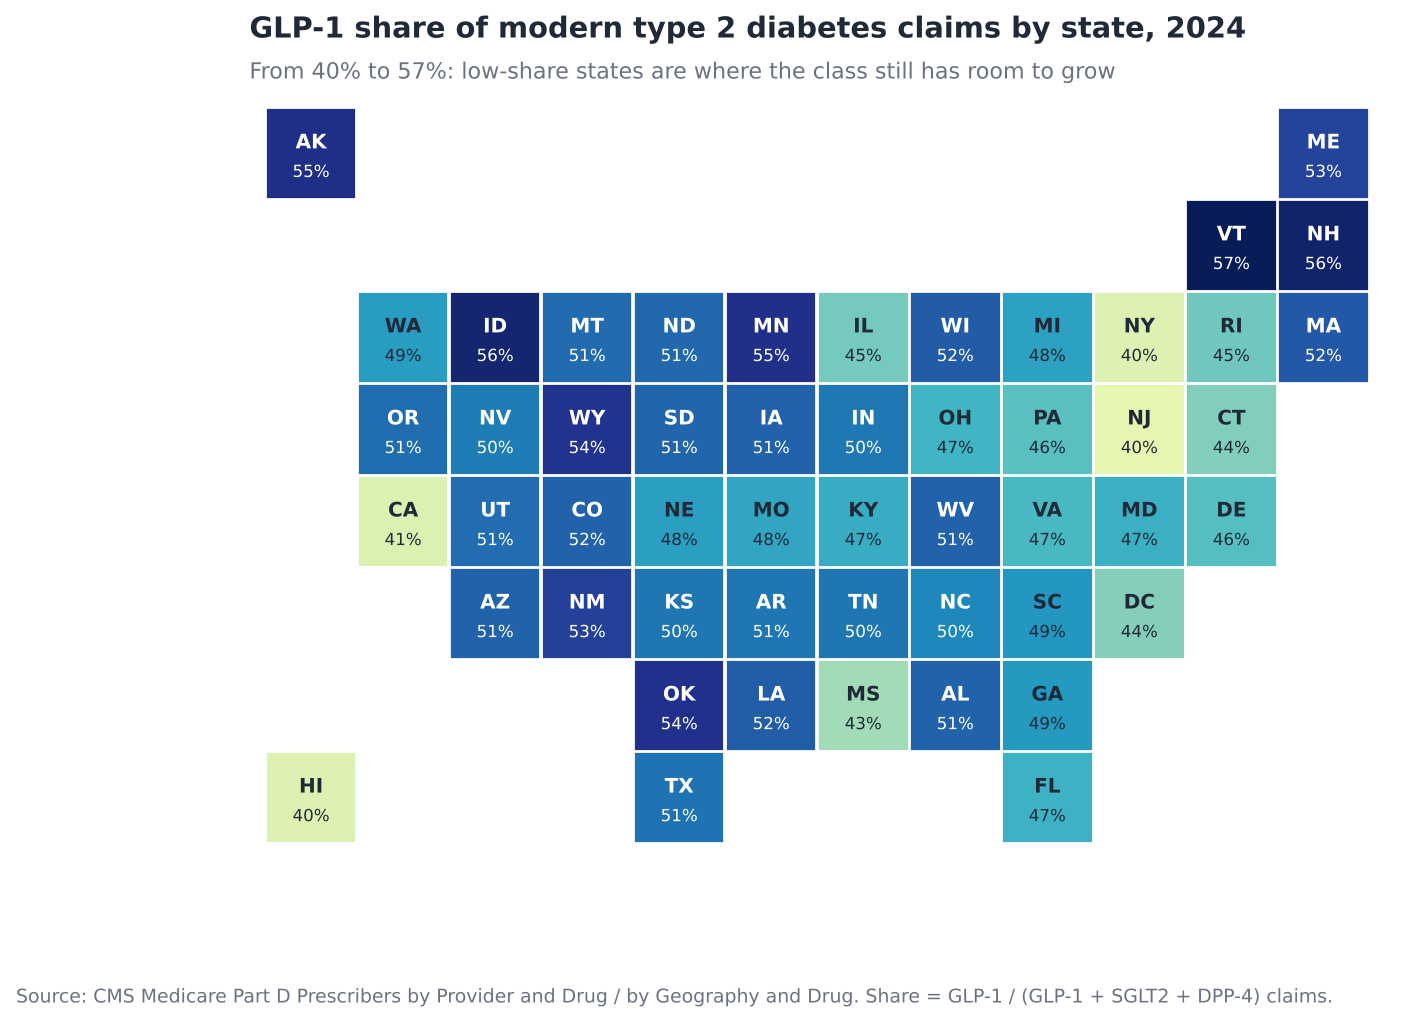

cls,GLP-1,SGLT2,DPP-4,glp1_share
Prscrbr_Geo_Desc,,,,
New Jersey,510576,485873,283822,0.399
Hawaii,66523,72412,25723,0.404
New York,1486368,1402071,790570,0.404
California,1884604,1945851,816794,0.406
Mississippi,254587,250799,84867,0.431
District of Columbia,34161,31241,12021,0.441
Connecticut,267064,224054,112053,0.443
Illinois,712189,645237,235071,0.447
Rhode Island,68159,65800,17680,0.449


In [5]:
st = geo[(geo["Prscrbr_Geo_Lvl"] == "State") & (geo["year"] == geo["year"].max())]
pen = st.pivot_table(index="Prscrbr_Geo_Desc", columns="cls", values="Tot_Clms", aggfunc="sum").fillna(0)
pen["glp1_share"] = pen["GLP-1"] / pen[["GLP-1", "SGLT2", "DPP-4"]].sum(axis=1)
pen = pen.sort_values("glp1_share")
pen.to_csv(TAB / "state_glp1_penetration.csv")

STATE_ABBR = {"Alabama": "AL", "Alaska": "AK", "Arizona": "AZ", "Arkansas": "AR", "California": "CA", "Colorado": "CO",
    "Connecticut": "CT", "Delaware": "DE", "District of Columbia": "DC", "Florida": "FL", "Georgia": "GA", "Hawaii": "HI",
    "Idaho": "ID", "Illinois": "IL", "Indiana": "IN", "Iowa": "IA", "Kansas": "KS", "Kentucky": "KY", "Louisiana": "LA",
    "Maine": "ME", "Maryland": "MD", "Massachusetts": "MA", "Michigan": "MI", "Minnesota": "MN", "Mississippi": "MS",
    "Missouri": "MO", "Montana": "MT", "Nebraska": "NE", "Nevada": "NV", "New Hampshire": "NH", "New Jersey": "NJ",
    "New Mexico": "NM", "New York": "NY", "North Carolina": "NC", "North Dakota": "ND", "Ohio": "OH", "Oklahoma": "OK",
    "Oregon": "OR", "Pennsylvania": "PA", "Rhode Island": "RI", "South Carolina": "SC", "South Dakota": "SD",
    "Tennessee": "TN", "Texas": "TX", "Utah": "UT", "Vermont": "VT", "Virginia": "VA", "Washington": "WA",
    "West Virginia": "WV", "Wisconsin": "WI", "Wyoming": "WY"}
# Tile-grid map: each state is one square, placed roughly where it sits on a map
TILES = {"AK": (0, 0), "ME": (0, 11), "VT": (1, 10), "NH": (1, 11), "WA": (2, 1), "ID": (2, 2), "MT": (2, 3), "ND": (2, 4),
    "MN": (2, 5), "IL": (2, 6), "WI": (2, 7), "MI": (2, 8), "NY": (2, 9), "RI": (2, 10), "MA": (2, 11), "OR": (3, 1),
    "NV": (3, 2), "WY": (3, 3), "SD": (3, 4), "IA": (3, 5), "IN": (3, 6), "OH": (3, 7), "PA": (3, 8), "NJ": (3, 9),
    "CT": (3, 10), "CA": (4, 1), "UT": (4, 2), "CO": (4, 3), "NE": (4, 4), "MO": (4, 5), "KY": (4, 6), "WV": (4, 7),
    "VA": (4, 8), "MD": (4, 9), "DE": (4, 10), "AZ": (5, 2), "NM": (5, 3), "KS": (5, 4), "AR": (5, 5), "TN": (5, 6),
    "NC": (5, 7), "SC": (5, 8), "DC": (5, 9), "OK": (6, 4), "LA": (6, 5), "MS": (6, 6), "AL": (6, 7), "GA": (6, 8),
    "HI": (7, 0), "TX": (7, 4), "FL": (7, 8)}

pen = pen[pen.index.isin(STATE_ABBR)]          # 50 states + DC; territories and 'Unknown' dropped
pen.to_csv(TAB / "state_glp1_penetration.csv")
vals = {STATE_ABBR[s]: v for s, v in pen["glp1_share"].items()}
lo, hi = min(vals.values()), max(vals.values())
cmap = plt.get_cmap("YlGnBu")
fig, ax = plt.subplots(figsize=(10, 6.2))
for abbr, (r, c) in TILES.items():
    v = vals.get(abbr)
    color = cmap(0.15 + 0.85 * (v - lo) / (hi - lo)) if v is not None else "#F3F4F6"
    ax.add_patch(plt.Rectangle((c, -r), 0.94, 0.94, color=color))
    ax.text(c + 0.47, -r + 0.58, abbr, ha="center", va="center", fontsize=9, fontweight="bold",
            color="white" if v is not None and (v - lo) / (hi - lo) > 0.55 else style.INK)
    if v is not None:
        ax.text(c + 0.47, -r + 0.26, f"{v:.0%}", ha="center", va="center", fontsize=7.5,
                color="white" if (v - lo) / (hi - lo) > 0.55 else style.INK)
ax.set_xlim(-0.2, 12.2)
ax.set_ylim(-7.2, 1.1)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title(f"GLP-1 share of modern type 2 diabetes claims by state, {st['year'].iloc[0]}")
style.subtitle(ax, f"From {lo:.0%} to {hi:.0%}: low-share states are where the class still has room to grow")
style.source(fig, SRC + ". Share = GLP-1 / (GLP-1 + SGLT2 + DPP-4) claims.")
style.save(fig, FIG / "02_state_glp1_penetration.png")
pen[["GLP-1", "SGLT2", "DPP-4", "glp1_share"]].round(3).head(10)

## 3. Who prescribes: specialty mix and concentration

Endocrinologists are the obvious target, but they write a minority of claims.

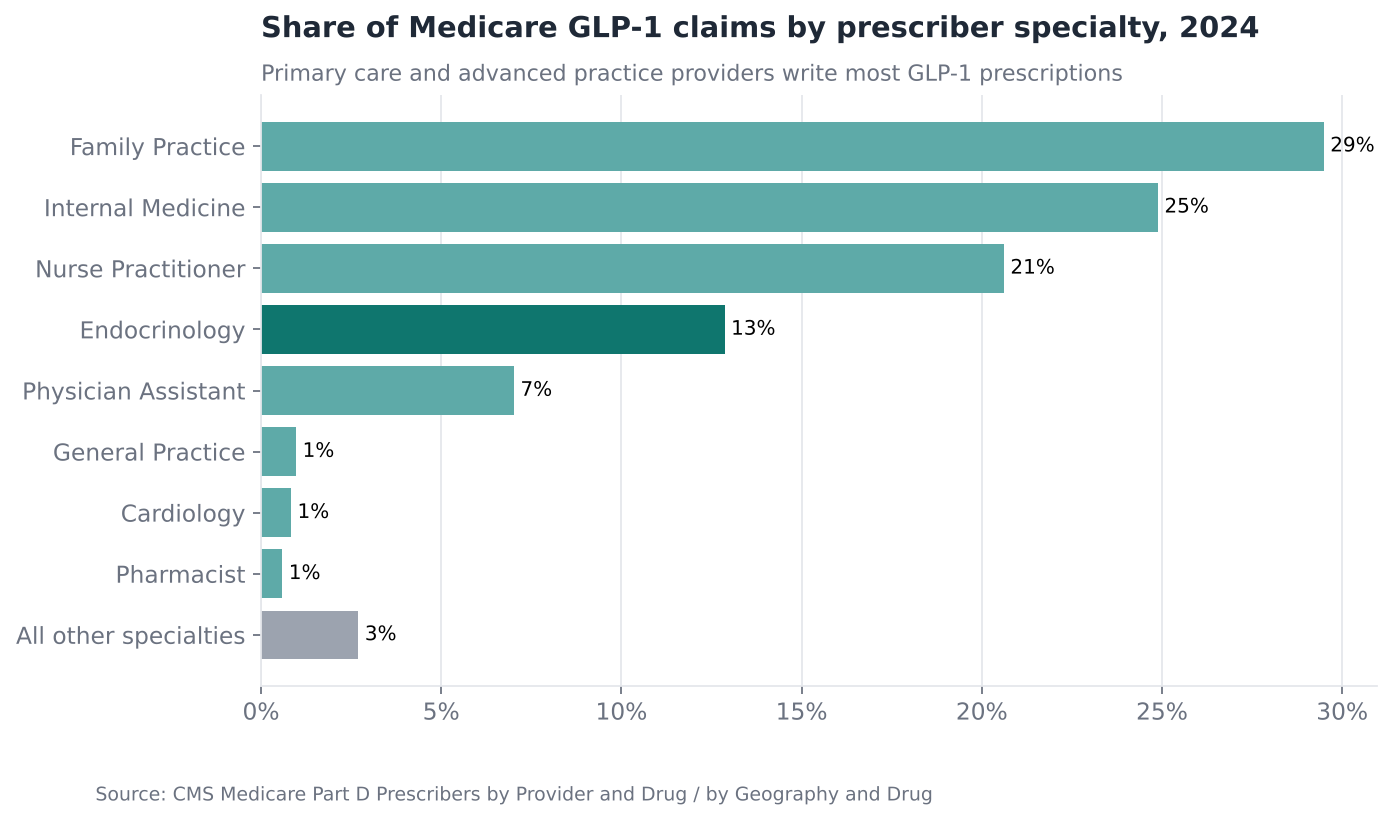

Prscrbr_Type
Family Practice        0.295
Internal Medicine      0.249
Nurse Practitioner     0.206
Endocrinology          0.129
Physician Assistant    0.070
General Practice       0.010
Cardiology             0.008
Pharmacist             0.006
Nephrology             0.004
Geriatric Medicine     0.003
Emergency Medicine     0.003
Hospitalist            0.003
Name: Tot_Clms, dtype: float64

In [6]:
YEAR = 2024
hcp_drug = load(RAW / f"prescriber_drug_{YEAR}.csv.gz")
glp = hcp_drug[hcp_drug["cls"] == "GLP-1"]
spec = glp.groupby("Prscrbr_Type")["Tot_Clms"].sum().sort_values(ascending=False)
spec_share = spec / spec.sum()
top_spec = spec_share.head(8)
other = 1 - top_spec.sum()

fig, ax = plt.subplots(figsize=(9, 4.8))
labels = list(top_spec.index[::-1])
ax.barh(["All other specialties"] + labels, [other] + list(top_spec.values[::-1]),
        color=[style.NEUTRAL] + [style.ACCENT if "Endocrin" in l else "#5EAAA8" for l in labels])
for y, v in enumerate([other] + list(top_spec.values[::-1])):
    ax.text(v, y, f" {v:.0%}", va="center", fontsize=9)
ax.set_title(f"Share of Medicare GLP-1 claims by prescriber specialty, {YEAR}")
style.subtitle(ax, "Primary care and advanced practice providers write most GLP-1 prescriptions")
style.pct(ax, "x")
ax.grid(axis="y", visible=False)
style.source(fig, SRC)
style.save(fig, FIG / "03_specialty_mix.png")
spec_share.head(12).round(3)

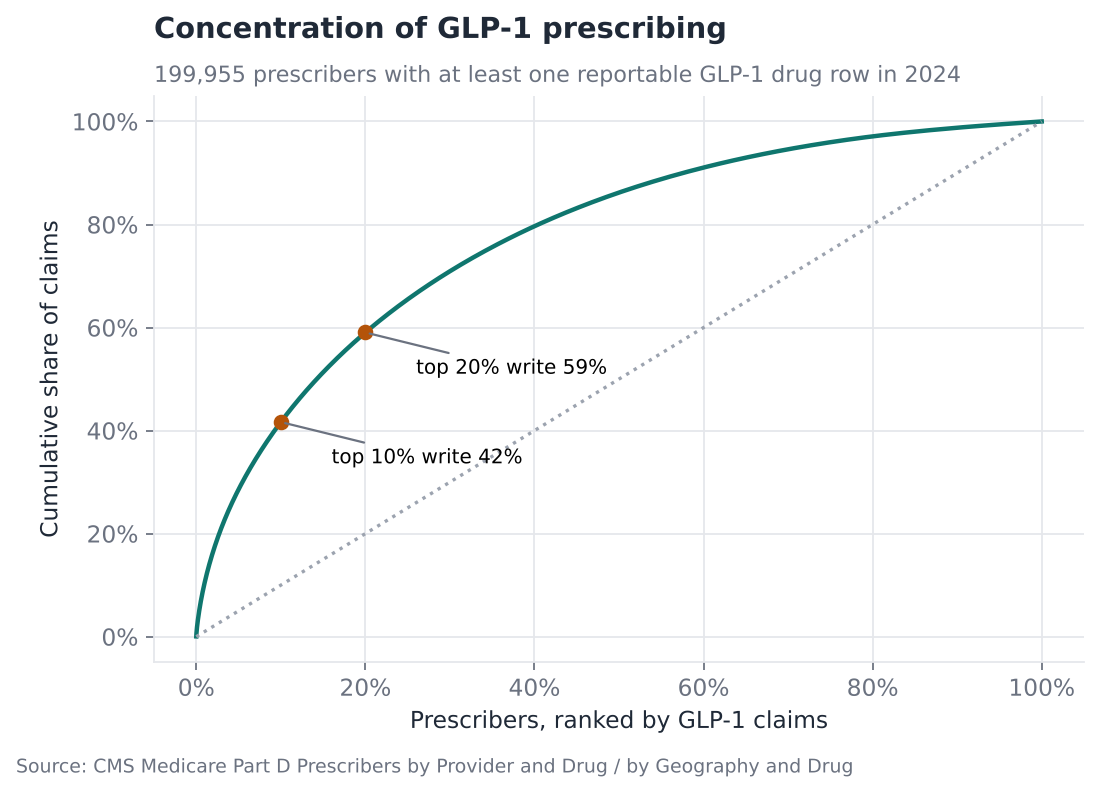

{'top 5% of prescribers': 0.2856492297335097,
 'top 10% of prescribers': 0.4165439760581298,
 'top 20% of prescribers': 0.5903905400454826}

In [7]:
per_hcp = glp.groupby("Prscrbr_NPI")["Tot_Clms"].sum().sort_values(ascending=False)
cum = per_hcp.cumsum() / per_hcp.sum()
n = len(per_hcp)
conc = {f"top {p:.0%} of prescribers": float(cum.iloc[int(n * p) - 1]) for p in (0.05, 0.10, 0.20)}

fig, ax = plt.subplots(figsize=(7.5, 4.6))
x = np.arange(1, n + 1) / n
ax.plot(x, cum.values, color=style.ACCENT, lw=2)
ax.plot([0, 1], [0, 1], color=style.NEUTRAL, ls=":")
for p, v in [(0.1, conc["top 10% of prescribers"]), (0.2, conc["top 20% of prescribers"])]:
    ax.scatter([p], [v], color=style.ACCENT_2, zorder=3)
    ax.annotate(f"top {p:.0%} write {v:.0%}", (p, v), xytext=(p + 0.06, v - 0.08), fontsize=9,
                arrowprops=dict(arrowstyle="-", color=style.MUTED))
ax.set_title("Concentration of GLP-1 prescribing")
style.subtitle(ax, f"{n:,} prescribers with at least one reportable GLP-1 drug row in {YEAR}")
style.pct(ax, "x"); style.pct(ax, "y")
ax.set_xlabel("Prescribers, ranked by GLP-1 claims")
ax.set_ylabel("Cumulative share of claims")
style.source(fig, SRC)
style.save(fig, FIG / "04_prescriber_concentration.png")
conc

## 4. Segment prescribers by potential and adoption

The universe is every prescriber in a **diabetes-managing specialty** (family
and internal medicine, general practice, geriatrics, endocrinology, nurse
practitioners and physician assistants) with reportable claims for any GLP-1,
SGLT2 or DPP-4 drug in 2024. Cardiologists and nephrologists are left out on
purpose: they write SGLT2 inhibitors mainly for heart failure and kidney
disease, so a low GLP-1 share there is not under-use in diabetes. They are a
separate audience for the cardiovascular and kidney indications that
semaglutide has added.

Two measures define the segments:

- **Potential**: decile of the prescriber's total modern diabetes claims
  (GLP-1 + SGLT2 + DPP-4). Decile 10 is the busiest 10% of prescribers.
- **Adoption**: the prescriber's GLP-1 share of those claims.

| Segment | Rule | What reps should do |
|---|---|---|
| **Champions** | Decile 8–10, adoption at or above the universe median | Protect and retain |
| **Growth targets** | Decile 8–10, adoption below the median | First call priority: big diabetes practice, under-using GLP-1s |
| **Steady adopters** | Decile 1–7, adoption at or above median | Lower-cost channels (email, virtual) |
| **Low priority** | Decile 1–7, adoption below median | Non-personal promotion only |

Rule-based segments are used instead of clustering because a field team needs
to understand, and trust, why a doctor is on their list.

In [8]:
hcp = (hcp_drug[hcp_drug["cls"].isin(["GLP-1", "SGLT2", "DPP-4"])]
       .pivot_table(index="Prscrbr_NPI", columns="cls", values="Tot_Clms", aggfunc="sum", fill_value=0))
info = hcp_drug.drop_duplicates("Prscrbr_NPI").set_index("Prscrbr_NPI")[["Prscrbr_Type", "Prscrbr_City", "Prscrbr_State_Abrvtn"]]
hcp = hcp.join(info)
DIABETES_SPECIALTIES = {"Family Practice", "Internal Medicine", "Nurse Practitioner", "Physician Assistant",
                        "Endocrinology", "General Practice", "Geriatric Medicine", "Family Medicine"}
excluded = hcp[~hcp["Prscrbr_Type"].isin(DIABETES_SPECIALTIES)]
print(f"Left out of the universe: {len(excluded):,} prescribers in other specialties; top ones:")
print(excluded["Prscrbr_Type"].value_counts().head(5).to_string())
hcp = hcp[hcp["Prscrbr_Type"].isin(DIABETES_SPECIALTIES)].copy()
hcp["modern_claims"] = hcp[["GLP-1", "SGLT2", "DPP-4"]].sum(axis=1)
hcp["glp1_share"] = hcp["GLP-1"] / hcp["modern_claims"]
hcp["decile"] = pd.qcut(hcp["modern_claims"].rank(method="first"), 10, labels=range(1, 11)).astype(int)
median_share = hcp["glp1_share"].median()
high = hcp["decile"] >= 8
adopt = hcp["glp1_share"] >= median_share
hcp["segment"] = np.select([high & adopt, high & ~adopt, ~high & adopt],
                           ["Champions", "Growth targets", "Steady adopters"], "Low priority")

seg = hcp.groupby("segment").agg(prescribers=("modern_claims", "size"),
                                 modern_claims=("modern_claims", "sum"),
                                 glp1_claims=("GLP-1", "sum"))
seg["share_of_prescribers"] = seg["prescribers"] / seg["prescribers"].sum()
seg["share_of_modern_claims"] = seg["modern_claims"] / seg["modern_claims"].sum()
seg["glp1_share"] = seg["glp1_claims"] / seg["modern_claims"]
seg = seg.loc[["Champions", "Growth targets", "Steady adopters", "Low priority"]]
print(f"Universe: {len(hcp):,} prescribers; median GLP-1 share {median_share:.0%}")
seg.round(3)

Left out of the universe: 37,716 prescribers in other specialties; top ones:
Prscrbr_Type
Cardiology                                                        13247
Nephrology                                                         6624
Student in an Organized Health Care Education/Training Program     3922
Interventional Cardiology                                          3027
Hospitalist                                                        2065
Universe: 231,338 prescribers; median GLP-1 share 52%


,prescribers,modern_claims,glp1_claims,share_of_prescribers,share_of_modern_claims,glp1_share
segment,,,,,,
Champions,36609,14881407,9730338,0.158,0.392,0.654
Growth targets,32793,12829921,4244849,0.142,0.338,0.331
Steady adopters,79060,5209551,3830466,0.342,0.137,0.735
Low priority,82876,4998600,1244810,0.358,0.132,0.249


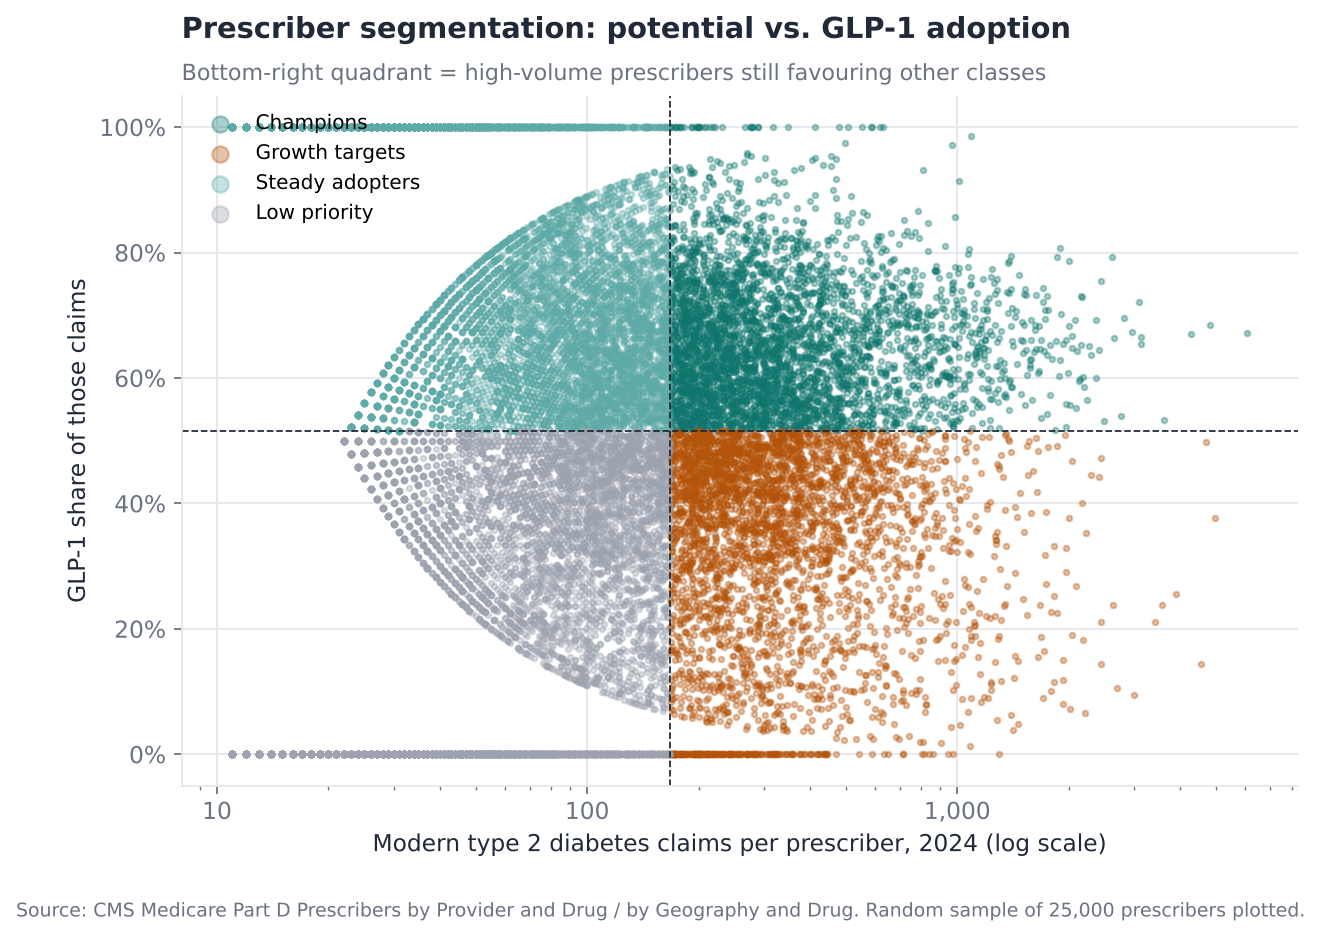

In [9]:
sample = hcp.sample(min(len(hcp), 25000), random_state=7)
seg_colors = {"Champions": style.ACCENT, "Growth targets": style.ACCENT_2,
              "Steady adopters": "#5EAAA8", "Low priority": style.NEUTRAL}
fig, ax = plt.subplots(figsize=(9, 5.6))
for s, c in seg_colors.items():
    d = sample[sample["segment"] == s]
    ax.scatter(d["modern_claims"], d["glp1_share"], s=6, alpha=0.35, color=c, label=s, rasterized=True)
d8 = hcp.loc[hcp["decile"] == 8, "modern_claims"].min()
ax.axvline(d8, color=style.INK, lw=0.8, ls="--")
ax.axhline(median_share, color=style.INK, lw=0.8, ls="--")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel("Modern type 2 diabetes claims per prescriber, 2024 (log scale)")
ax.set_ylabel("GLP-1 share of those claims")
style.pct(ax)
ax.set_title("Prescriber segmentation: potential vs. GLP-1 adoption")
style.subtitle(ax, "Bottom-right quadrant = high-volume prescribers still favouring other classes")
ax.legend(loc="upper left", markerscale=3, fontsize=9)
style.source(fig, SRC + ". Random sample of 25,000 prescribers plotted.")
style.save(fig, FIG / "05_segmentation.png")

## 5. Size the opportunity in the growth-target segment

If each growth target moved to the **median GLP-1 share of champions**, how many
extra GLP-1 claims would that be? Value is shown at the 2024 average gross cost
per GLP-1 claim, so it is an upper bound on gross sales, not net revenue.

In [10]:
champ_share = hcp.loc[hcp["segment"] == "Champions", "glp1_share"].median()
cost_per_claim = glp["Tot_Drug_Cst"].sum() / glp["Tot_Clms"].sum()
tg = hcp[hcp["segment"] == "Growth targets"].copy()
tg["incremental_claims"] = ((champ_share - tg["glp1_share"]).clip(lower=0) * tg["modern_claims"])
tg["incremental_gross_cost"] = tg["incremental_claims"] * cost_per_claim
tg = tg.sort_values("incremental_claims", ascending=False)
tg["cum_share_of_opportunity"] = tg["incremental_claims"].cumsum() / tg["incremental_claims"].sum()
opp = {
    "growth_targets": len(tg),
    "champion_median_share": round(float(champ_share), 3),
    "incremental_claims": int(tg["incremental_claims"].sum()),
    "avg_gross_cost_per_glp1_claim": round(float(cost_per_claim), 0),
    "incremental_gross_cost_usd": int(tg["incremental_gross_cost"].sum()),
    "targets_for_half_of_opportunity": int((tg["cum_share_of_opportunity"] <= 0.5).sum() + 1),
}
opp

{'growth_targets': 32793,
 'champion_median_share': 0.642,
 'incremental_claims': 3997837,
 'avg_gross_cost_per_glp1_claim': 1253.0,
 'incremental_gross_cost_usd': 5007699866,
 'targets_for_half_of_opportunity': 6738}

In [11]:
tspec = (tg.groupby("Prscrbr_Type")["incremental_claims"].sum().sort_values(ascending=False) / tg["incremental_claims"].sum())
tspec.head(8).round(3)

Prscrbr_Type
Internal Medicine      0.425
Family Practice        0.307
Nurse Practitioner     0.138
Physician Assistant    0.044
General Practice       0.039
Endocrinology          0.036
Geriatric Medicine     0.010
Family Medicine        0.001
Name: incremental_claims, dtype: float64

Target list: the 1,000 growth targets with the largest opportunity. Names are
left out on purpose; the NPI (National Provider Identifier) links back to the
public CMS record for anyone who needs it.

In [12]:
cols = ["Prscrbr_Type", "Prscrbr_City", "Prscrbr_State_Abrvtn", "decile", "modern_claims", "GLP-1", "SGLT2", "DPP-4",
        "glp1_share", "incremental_claims", "incremental_gross_cost"]
target_list = tg.head(1000)[cols].round({"glp1_share": 3, "incremental_claims": 0, "incremental_gross_cost": 0})
target_list.to_csv(TAB / "growth_target_list_top1000.csv")
seg.to_csv(TAB / "segment_summary.csv")
target_list.head(15)

,Prscrbr_Type,Prscrbr_City,Prscrbr_State_Abrvtn,decile,modern_claims,GLP-1,SGLT2,DPP-4,glp1_share,incremental_claims,incremental_gross_cost
Prscrbr_NPI,,,,,,,,,,,
1619082625,Internal Medicine,Rego Park,NY,10,17762,6697,7164,3901,0.377,4714.0,5905193.0
1093813099,Internal Medicine,Town And Country,MO,10,4944,264,3017,1663,0.053,2912.0,3647969.0
1265445894,Endocrinology,Flushing,NY,10,5027,432,2868,1727,0.086,2798.0,3504326.0
1598788689,Internal Medicine,Plymouth Meeting,PA,10,7035,1965,3065,2005,0.279,2555.0,3200013.0
1710074026,Internal Medicine,Los Angeles,CA,10,4385,487,2849,1049,0.111,2330.0,2918787.0
1922091784,Endocrinology,Caguas,PR,10,4563,655,2615,1293,0.144,2277.0,2851594.0
1285746511,Family Practice,Jackson,MS,10,3932,338,1291,2303,0.086,2188.0,2740875.0
1326072612,Internal Medicine,Santa Ana,CA,10,4738,913,2278,1547,0.193,2131.0,2669253.0
1982659660,Endocrinology,Brooklyn,NY,10,6777,2232,2119,2426,0.329,2122.0,2657945.0


## 6. Brand view: where Mounjaro is under-indexed

A second lens for one brand team. Among prescribers writing at least 50 GLP-1
claims, what share goes to Mounjaro (tirzepatide)? "None reported" means fewer
than 11 Mounjaro claims, since CMS suppresses smaller counts. High-volume GLP-1 writers who
rarely use Mounjaro are conversion targets for its team. The same logic could
be run for any brand.

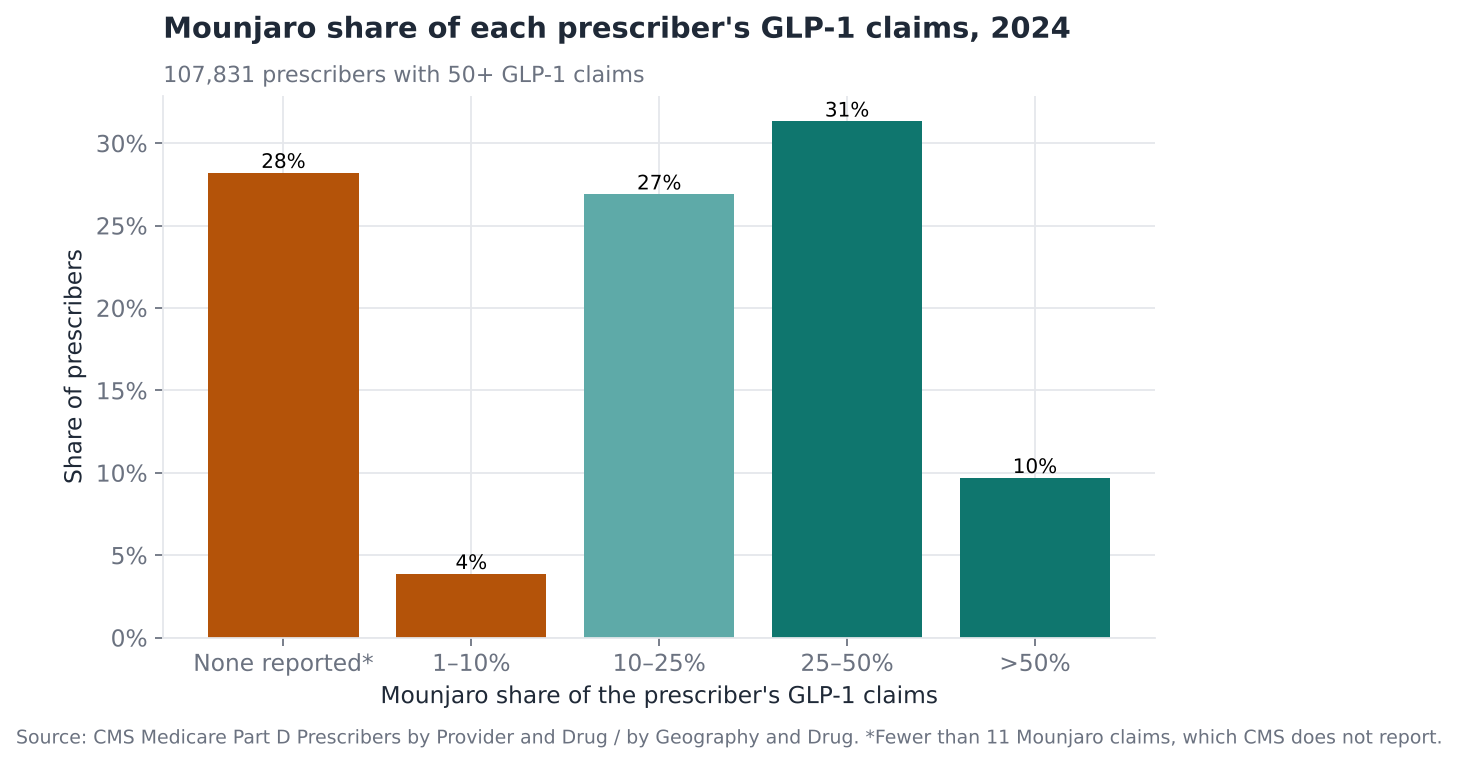

,prescribers,glp1_claims,share_of_prescribers
mounjaro_share,,,
None reported*,30416,2863578,0.282
1–10%,4174,1140878,0.039
10–25%,29008,5442407,0.269
25–50%,33778,6328708,0.313
>50%,10455,1712566,0.097


In [13]:
gl = glp.pivot_table(index="Prscrbr_NPI", columns="brand", values="Tot_Clms", aggfunc="sum", fill_value=0)
gl["total"] = gl.sum(axis=1)
gl = gl[gl["total"] >= 50]
gl["mounjaro_share"] = gl.get("Mounjaro", 0) / gl["total"]
bins = pd.cut(gl["mounjaro_share"], [-0.001, 0.0, 0.1, 0.25, 0.5, 1.0],
              labels=["None reported*", "1–10%", "10–25%", "25–50%", ">50%"])
dist = gl.groupby(bins, observed=False)["total"].agg(["size", "sum"])
dist.columns = ["prescribers", "glp1_claims"]
dist["share_of_prescribers"] = dist["prescribers"] / dist["prescribers"].sum()

fig, ax = plt.subplots(figsize=(8, 4.4))
ax.bar(dist.index.astype(str), dist["share_of_prescribers"],
       color=[style.ACCENT_2, style.ACCENT_2, "#5EAAA8", style.ACCENT, style.ACCENT])
for i, v in enumerate(dist["share_of_prescribers"]):
    ax.text(i, v, f"{v:.0%}", ha="center", va="bottom", fontsize=9)
ax.set_title(f"Mounjaro share of each prescriber's GLP-1 claims, {YEAR}")
style.subtitle(ax, f"{len(gl):,} prescribers with 50+ GLP-1 claims")
style.pct(ax)
ax.set_xlabel("Mounjaro share of the prescriber's GLP-1 claims")
ax.set_ylabel("Share of prescribers")
style.source(fig, SRC + ". *Fewer than 11 Mounjaro claims, which CMS does not report.")
style.save(fig, FIG / "06_mounjaro_share_distribution.png")
dist.round(3)

## 7. Momentum: which prescribers are growing GLP-1 use fastest?

In [14]:
def glp_by_npi(year):
    d = load(RAW / f"prescriber_drug_{year}.csv.gz")
    return d[d["cls"] == "GLP-1"].groupby("Prscrbr_NPI")["Tot_Clms"].sum()

hist = pd.concat({y: glp_by_npi(y) for y in (2022, 2023, 2024)}, axis=1).fillna(0)
both = hist[(hist[2023] > 0) & (hist[2024] > 0)]
yoy = (hist[2024].sum() / hist[2023].sum() - 1)
new_writers = int(((hist[2023] == 0) & (hist[2024] > 0)).sum())
new_writer_claims = hist.loc[(hist[2023] == 0) & (hist[2024] > 0), 2024].sum() / hist[2024].sum()
growth_src = {
    "glp1_claims_2022": int(hist[2022].sum()), "glp1_claims_2023": int(hist[2023].sum()),
    "glp1_claims_2024": int(hist[2024].sum()), "yoy_growth_2024": round(float(yoy), 3),
    "new_reportable_writers_2024": new_writers, "share_of_2024_claims_from_new_writers": round(float(new_writer_claims), 3),
    "growth_from_existing_writers": round(float((both[2024].sum() - both[2023].sum()) / (hist[2024].sum() - hist[2023].sum())), 3),
}
growth_src

{'glp1_claims_2022': 8534110,
 'glp1_claims_2023': 14291710,
 'glp1_claims_2024': 19809313,
 'yoy_growth_2024': 0.386,
 'new_reportable_writers_2024': 49692,
 'share_of_2024_claims_from_new_writers': 0.074,
 'growth_from_existing_writers': 0.841}

## 8. Machine learning extension: who will add the most GLP-1 volume next year?

The segments above describe where prescribers are today. A field team also
wants to know **who is about to grow**, because calls are worth most just
before a prescriber accelerates.

**Set-up:**
- **Universe:** diabetes-specialty prescribers with reportable GLP-1 claims in 2023.
- **Target:** the *top growers*, the 10% of prescribers who added the most
  GLP-1 claims from 2023 to 2024 (absolute claims, because that is what a brand
  books).
- **Features (all known at the end of 2023):** GLP-1 claims and patients,
  2022→2023 momentum, whether the prescriber was new to GLP-1s, number of
  brands used, Ozempic / Mounjaro / Trulicity mix, cost per claim, refills per
  patient, specialty, state and the state's GLP-1 penetration.
- **Validation:** 5-fold cross-validation **grouped by state**. The model is
  always scored on states it did not learn from, which is the harder and more
  honest test for a territory-level tool.

**Model:** gradient-boosted decision trees (`HistGradientBoostingClassifier`).
The model builds hundreds of small decision trees, each correcting the errors of the
ones before. **Baseline:** ranking prescribers by current GLP-1 volume, which is
what most targeting already does.

**Terms:** *AUC* (area under the ROC curve) is the chance that the model ranks
a random top grower above a random other prescriber; 0.5 is a coin flip.
*Capture* is the share of all next-year growth reached by calling the top X%
of the ranked list.

In [15]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.inspection import permutation_importance
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score

DIAB_SPEC = DIABETES_SPECIALTIES


def state_penetration(year):
    g = geo[(geo["Prscrbr_Geo_Lvl"] == "State") & (geo["year"] == year)]
    p = g.pivot_table(index="Prscrbr_Geo_Desc", columns="cls", values="Tot_Clms", aggfunc="sum").fillna(0)
    p = p["GLP-1"] / p[["GLP-1", "SGLT2", "DPP-4"]].sum(axis=1)
    return p.rename(index=STATE_ABBR)


claims_by_year = {y: load(RAW / f"prescriber_drug_{y}.csv.gz").query("cls == 'GLP-1'").groupby("Prscrbr_NPI")["Tot_Clms"].sum()
                  for y in (2022, 2023, 2024)}


def features(year):
    d = load(RAW / f"prescriber_drug_{year}.csv.gz")
    d = d[(d["cls"] == "GLP-1") & d["Prscrbr_Type"].isin(DIAB_SPEC)]
    f = d.groupby("Prscrbr_NPI").agg(glp1_claims=("Tot_Clms", "sum"), glp1_benes=("Tot_Benes", "sum"),
                                     glp1_cost=("Tot_Drug_Cst", "sum"), n_brands=("brand", "nunique"),
                                     specialty=("Prscrbr_Type", "first"), state=("Prscrbr_State_Abrvtn", "first"))
    mix = d.pivot_table(index="Prscrbr_NPI", columns="brand", values="Tot_Clms", aggfunc="sum", fill_value=0)
    for b in ["Ozempic", "Mounjaro", "Trulicity"]:
        f[f"share_{b.lower()}"] = (mix[b] if b in mix else 0) / f["glp1_claims"]
    f["cost_per_claim"] = f["glp1_cost"] / f["glp1_claims"]
    f["claims_per_patient"] = f["glp1_claims"] / f["glp1_benes"].clip(lower=1)
    f["state_penetration"] = f["state"].map(state_penetration(year))
    prev = claims_by_year[year - 1].reindex(f.index).fillna(0)
    f["log_claims"] = np.log1p(f["glp1_claims"])
    f["momentum"] = np.log1p(f["glp1_claims"]) - np.log1p(prev)
    f["new_to_glp1"] = (prev == 0).astype(int)
    return f.drop(columns=["glp1_cost"])


FEATS = ["log_claims", "glp1_benes", "momentum", "new_to_glp1", "n_brands", "share_ozempic", "share_mounjaro",
         "share_trulicity", "cost_per_claim", "claims_per_patient", "state_penetration"]
CAT = ["specialty", "state"]
F23 = features(2023)
F24 = features(2024)
cats = {c: sorted(set(F23[c].dropna()) | set(F24[c].dropna())) for c in CAT}


def matrix(f):
    X = f[FEATS].copy()
    for c in CAT:
        X[c] = pd.Categorical(f[c], categories=cats[c]).codes
    return X


def make_model():
    return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=31,
                                          categorical_features=[len(FEATS) + i for i in range(len(CAT))],
                                          random_state=7)


X = matrix(F23)
gain = claims_by_year[2024].reindex(F23.index).fillna(0) - F23["glp1_claims"]
y = (gain >= gain.quantile(0.9)).astype(int)

oof = np.zeros(len(X))
for tr, te in GroupKFold(n_splits=5).split(X, y, groups=F23["state"].fillna("NA")):
    oof[te] = make_model().fit(X.iloc[tr], y.iloc[tr]).predict_proba(X.iloc[te])[:, 1]


def capture(score, frac):
    order = np.argsort(-np.asarray(score))
    k = int(frac * len(order))
    return gain.values[order[:k]].clip(min=0).sum() / gain.clip(lower=0).sum()


vol = F23["glp1_claims"].values
ml_eval = pd.DataFrame({
    "AUC": [roc_auc_score(y, oof), roc_auc_score(y, vol)],
    "Top 10% capture": [capture(oof, 0.1), capture(vol, 0.1)],
    "Top 20% capture": [capture(oof, 0.2), capture(vol, 0.2)],
}, index=["Gradient boosting", "Rank by current volume"])
print(f"{len(X):,} prescribers; a top grower added at least {gain.quantile(0.9):.0f} claims in 2024")
ml_eval.round(3)

162,410 prescribers; a top grower added at least 84 claims in 2024


,AUC,Top 10% capture,Top 20% capture
Gradient boosting,0.816,0.289,0.436
Rank by current volume,0.780,0.254,0.396


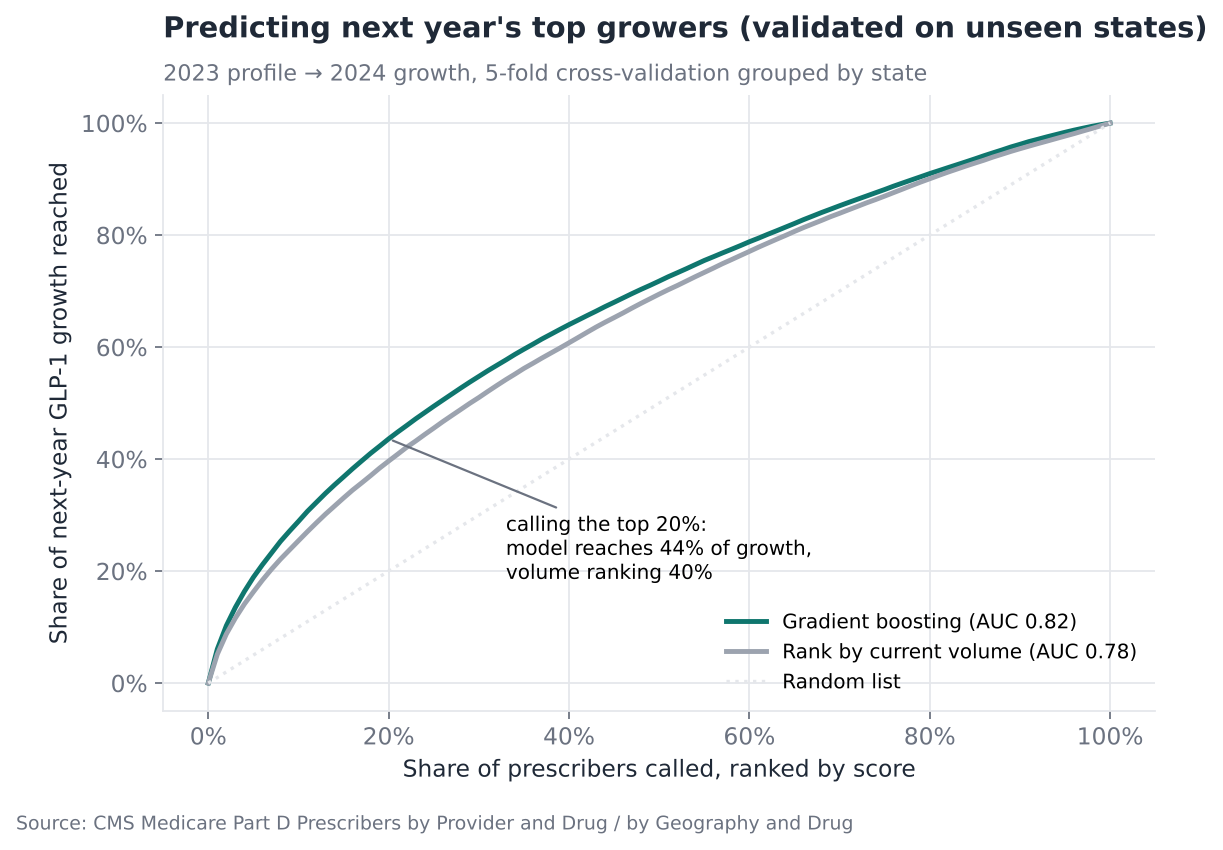

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
xs = np.linspace(0, 1, 101)
for name, s, c in [("Gradient boosting", oof, style.ACCENT), ("Rank by current volume", vol, style.NEUTRAL)]:
    ax.plot(xs, [capture(s, x) if x > 0 else 0 for x in xs], color=c, lw=2.2,
            label=f"{name} (AUC {ml_eval.loc[name, 'AUC']:.2f})")
ax.plot([0, 1], [0, 1], color=style.GRID, ls=":", label="Random list")
c20m, c20v = ml_eval.loc["Gradient boosting", "Top 20% capture"], ml_eval.loc["Rank by current volume", "Top 20% capture"]
ax.annotate(f"calling the top 20%:\nmodel reaches {c20m:.0%} of growth,\nvolume ranking {c20v:.0%}", (0.2, c20m),
            xytext=(0.33, c20m - 0.25), fontsize=9, arrowprops=dict(arrowstyle="-", color=style.MUTED))
style.pct(ax, "x"); style.pct(ax, "y")
ax.set_xlabel("Share of prescribers called, ranked by score")
ax.set_ylabel("Share of next-year GLP-1 growth reached")
ax.set_title("Predicting next year's top growers (validated on unseen states)")
style.subtitle(ax, "2023 profile → 2024 growth, 5-fold cross-validation grouped by state")
ax.legend(loc="lower right", fontsize=9)
style.source(fig, SRC)
style.save(fig, FIG / "07_ml_growth_capture.png")

**What drives the prediction?** Permutation importance measures how much AUC
drops when one feature is randomly shuffled. A bigger drop means the model
relies on that feature more.

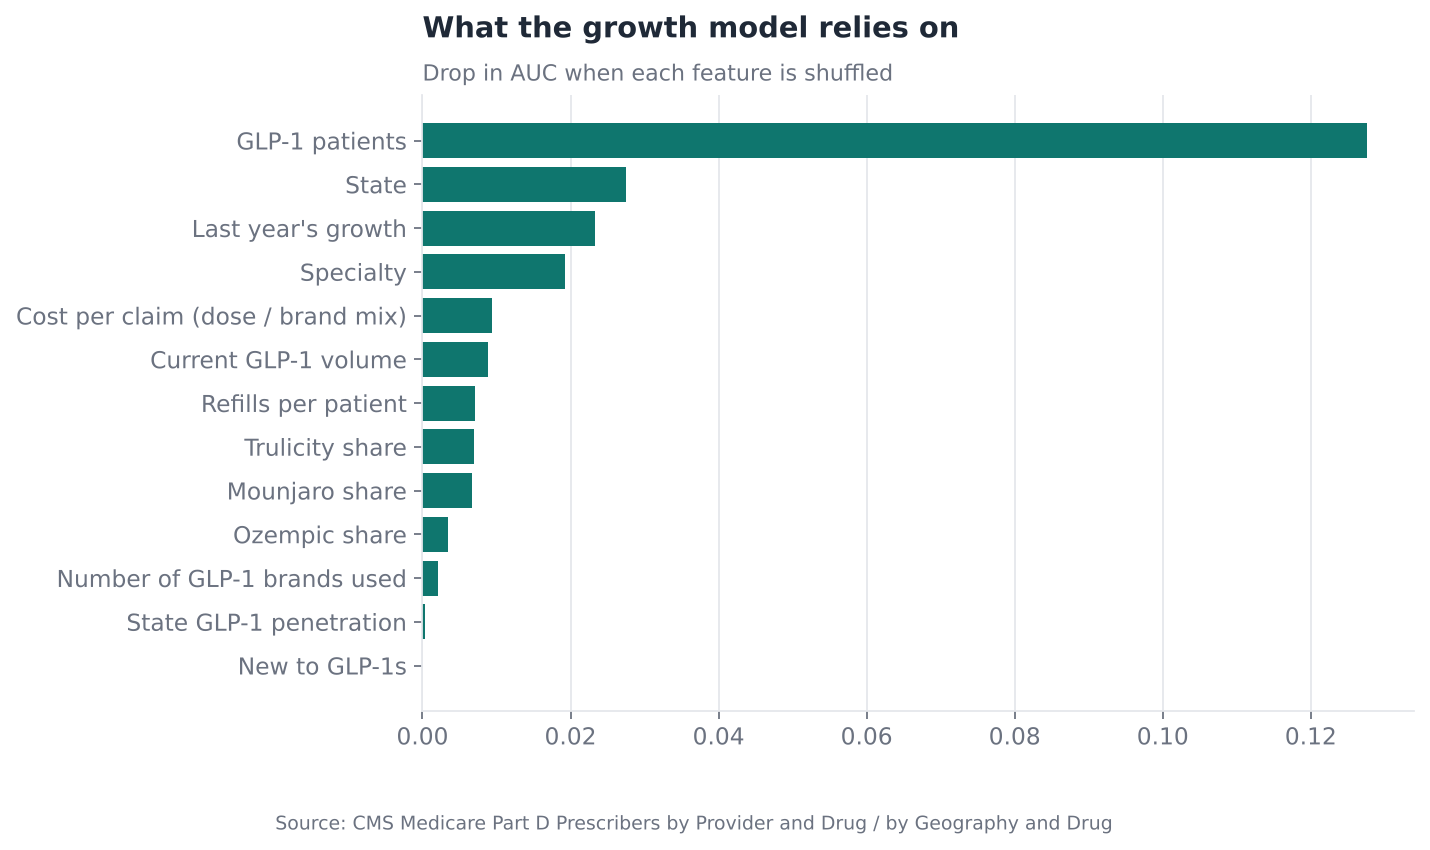

glp1_benes            0.1276
state                 0.0276
momentum              0.0232
specialty             0.0193
cost_per_claim        0.0094
log_claims            0.0089
claims_per_patient    0.0072
share_trulicity       0.0070
share_mounjaro        0.0067
share_ozempic         0.0034
n_brands              0.0021
state_penetration     0.0004
new_to_glp1           0.0000
dtype: float64

In [17]:
final = make_model().fit(X, y)
imp = permutation_importance(final, X, y, scoring="roc_auc", n_repeats=3, random_state=7, n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=X.columns).sort_values()
labels = {"log_claims": "Current GLP-1 volume", "glp1_benes": "GLP-1 patients", "momentum": "Last year's growth",
          "new_to_glp1": "New to GLP-1s", "n_brands": "Number of GLP-1 brands used",
          "share_ozempic": "Ozempic share", "share_mounjaro": "Mounjaro share", "share_trulicity": "Trulicity share",
          "cost_per_claim": "Cost per claim (dose / brand mix)", "claims_per_patient": "Refills per patient",
          "state_penetration": "State GLP-1 penetration", "specialty": "Specialty", "state": "State"}
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([labels[i] for i in imp.index], imp.values, color=style.ACCENT)
ax.set_title("What the growth model relies on")
style.subtitle(ax, "Drop in AUC when each feature is shuffled")
ax.grid(axis="y", visible=False)
style.source(fig, SRC)
style.save(fig, FIG / "08_ml_feature_importance.png")
imp.sort_values(ascending=False).round(4)

**Using it:** the model trained on 2023 → 2024 scores each prescriber's 2024
profile to rank likely 2025 top growers. The list is compared with the
rule-based growth-target segment from section 4. The two answer different
questions (who under-uses GLP-1s today vs. who is about to add the most
volume), so they work best together.

In [18]:
F24["growth_score"] = final.predict_proba(matrix(F24))[:, 1]
top_ml = F24.sort_values("growth_score", ascending=False).head(5000)
seg_of_top = hcp["segment"].reindex(top_ml.index).fillna("Not in 2024 universe").value_counts(normalize=True)
overlap = float(seg_of_top.get("Growth targets", 0))
ml_list = top_ml[["specialty", "state", "glp1_claims", "momentum", "share_ozempic", "share_mounjaro", "growth_score"]].round(3)
ml_list.to_csv(TAB / "ml_growth_scores_top5000.csv")
seg_of_top.round(3)

segment
Champions          0.838
Growth targets     0.123
Steady adopters    0.036
Low priority       0.003
Name: proportion, dtype: float64

### Check on the rule-based segments: does unsupervised clustering agree?

K-means clustering groups prescribers by similarity without being told the
segment rules. If it finds roughly the same four groups, the hand-made rules
match real structure in the data. The *adjusted Rand index* (ARI) scores
agreement between two groupings: 0 means chance, 1 means identical.

In [19]:
km_X = np.column_stack([np.log1p(hcp["modern_claims"]), hcp["glp1_share"],
                        hcp["SGLT2"] / hcp["modern_claims"], hcp["DPP-4"] / hcp["modern_claims"]])
km = KMeans(n_clusters=4, n_init=10, random_state=7).fit(StandardScaler().fit_transform(km_X))
hcp["cluster"] = km.labels_
ari = adjusted_rand_score(hcp["segment"], hcp["cluster"])
profile = hcp.groupby("cluster").agg(prescribers=("modern_claims", "size"),
                                     median_claims=("modern_claims", "median"),
                                     glp1_share=("glp1_share", "median"))
print(f"Adjusted Rand index, k-means vs rule segments: {ari:.2f}")
pd.crosstab(hcp["cluster"], hcp["segment"], normalize="index").round(2).join(profile)

Adjusted Rand index, k-means vs rule segments: 0.24


,Champions,Growth targets,Low priority,Steady adopters,prescribers,median_claims,glp1_share
cluster,,,,,,,
0,0.31,0.25,0.21,0.22,114662,188.0,0.5311
1,0.02,0.00,0.01,0.98,53599,36.0,1.0000
2,0.00,0.03,0.97,0.00,41882,29.0,0.0000
3,0.00,0.13,0.83,0.04,21195,49.0,0.0000


**Reading the result:** k-means does *not* reproduce the volume split.
Instead it isolates prescribers whose reportable claims sit in only one class
(GLP-1 share exactly 0% or 100%). That is mostly an artifact of CMS hiding
counts under 11, not a real prescribing style. So clustering adds no better
segmentation here, and the transparent rule-based segments are kept. Checking
this is still worth doing: an unsupervised method applied without this check
would have produced a misleading "segment".

## 9. Summary numbers used in the README

In [20]:
summary = {
    "spend_first_year": int(first), "spend_last_year": int(last),
    "glp1_spend_first": float(growth[first]), "glp1_spend_last": float(growth[last]),
    "glp1_spend_cagr": float((growth[last] / growth[first]) ** (1 / (last - first)) - 1),
    "state_share_min": float(lo), "state_share_max": float(hi),
    "state_lowest": pen.index[0], "state_highest": pen.index[-1],
    "endocrinology_share": float(spec_share[[s for s in spec_share.index if "Endocrin" in s]].sum()),
    "top10pct_prescriber_share": conc["top 10% of prescribers"],
    "universe_prescribers": int(len(hcp)), "median_glp1_share": float(median_share),
    **{f"seg_{k.lower().replace(' ', '_')}": int(v) for k, v in seg["prescribers"].items()},
    **opp, **growth_src,
    "mounjaro_low_share_prescribers": float(dist.loc[["None reported*", "1–10%"], "share_of_prescribers"].sum()),
    "mounjaro_none_reported": float(dist.loc["None reported*", "share_of_prescribers"]),
    "ml_n": int(len(X)), "ml_eval": ml_eval.round(4).to_dict(),
    "ml_top_features": imp.sort_values(ascending=False).head(4).index.tolist(),
    "ml_top5000_segments": seg_of_top.round(3).to_dict(),
    "ml_overlap_with_growth_targets": float(overlap), "kmeans_ari": float(ari),
}
pd.Series(summary).to_json(TAB / "summary.json", indent=1)
pd.Series(summary)

spend_first_year                                                                      2018
spend_last_year                                                                       2024
glp1_spend_first                                                             3662897040.63
glp1_spend_last                                                         27894727292.619999
glp1_spend_cagr                                                                   0.402651
state_share_min                                                                   0.398803
state_share_max                                                                   0.565986
state_lowest                                                                    New Jersey
state_highest                                                                      Vermont
endocrinology_share                                                               0.128663
top10pct_prescriber_share                                                         0.416544